# 02. Two-stage anchor-based detector: Faster R-CNN

**Question.** How well does a two-stage detector handle small, dense drone objects, and what do the region proposal network (RPN) and the second stage each contribute?

**Protocol** (shared by all detector notebooks): fold 0 of the five sequence-level folds, every 5th training frame, long side 1280, 12 epochs, COCO-pretrained weights, evaluation on test-like downscaled scored windows with ignored regions as crowd. Training runs: `visdet run configs/two_stage/<name>.yaml` (torchvision `fasterrcnn_resnet50_fpn_v2`, DDP on 3 GPUs).

In [1]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

os.environ.setdefault("VISDET_DATA", "../../hw2/data")
RUNS = Path(os.environ.get("VISDET_RUNS", "../../hw2/runs"))
from visdet.data.index import load_tables
from visdet.viz import gallery, results, style

style.apply()
tables = load_tables()
NAMES = [
    "faster-rcnn",
    "faster-rcnn-proposals",
    "faster-rcnn-sampling",
    "faster-rcnn-giou",
    "faster-rcnn-anchors",
]

## Experiments
| run | change from the baseline |
|---|---|
| faster-rcnn | torchvision defaults: 2000/1000 RPN proposals (train/test), 512 RoIs per image with 25% positives, smooth L1 box loss, anchors 32-512 |
| faster-rcnn-proposals | 4000 train / 3000 test proposals |
| faster-rcnn-sampling | 1024 RoIs per image with 50% positives |
| faster-rcnn-giou | GIoU loss for the second-stage boxes (loss modification) |
| faster-rcnn-anchors | RPN anchors halved to 16-256 |

In [2]:
results.run_table(RUNS, NAMES)

,mAP,AP50,AP75,AP_small,AP_medium,AP_large,ms_per_image
faster-rcnn,0.2358,0.4294,0.2283,0.0424,0.1912,0.3984,15.2
faster-rcnn-proposals,0.2486,0.4585,0.2387,0.0477,0.2024,0.4067,22.7
faster-rcnn-sampling,0.2370,0.4318,0.2298,0.0527,0.1870,0.3934,15.2
faster-rcnn-giou,0.2312,0.4283,0.2207,0.0525,0.1870,0.4040,15.2
faster-rcnn-anchors,0.2410,0.4546,0.2278,0.0537,0.2006,0.3990,15.4


In [3]:
results.class_table(RUNS, NAMES)

,person,bicycle,car,van,truck,tricycle,bus,motor
faster-rcnn,0.167,0.021,0.469,0.195,0.235,0.205,0.490,0.104
faster-rcnn-proposals,0.178,0.024,0.477,0.215,0.233,0.217,0.534,0.109
faster-rcnn-sampling,0.167,0.024,0.468,0.198,0.245,0.204,0.494,0.096
faster-rcnn-giou,0.167,0.024,0.468,0.176,0.230,0.216,0.471,0.098
faster-rcnn-anchors,0.174,0.038,0.465,0.194,0.263,0.221,0.468,0.106


## Validation mAP over training
mAP on a fixed subset of 300 scored frames after each epoch.

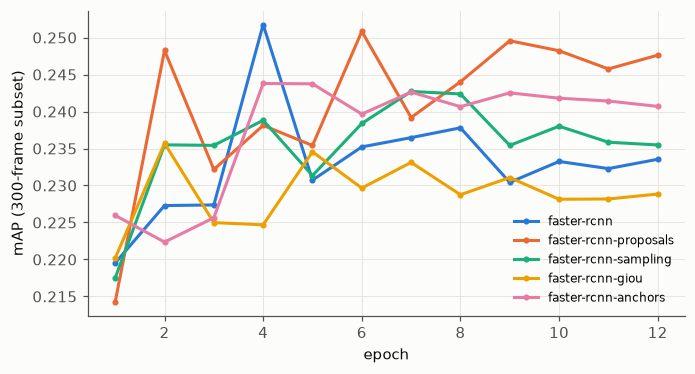

In [4]:
fig, ax = plt.subplots(figsize=(7, 3.6))
for i, name in enumerate(NAMES):
    path = RUNS / name / "fold0" / "val_curve.csv"
    if path.exists():
        curve = pd.read_csv(path)
        ax.plot(curve["epoch"], curve["mAP"], marker="o", ms=3, color=style.PALETTE[i], label=name)
ax.set_xlabel("epoch")
ax.set_ylabel("mAP (300-frame subset)")
ax.legend(frameon=False, fontsize=8);

## What each stage contributes
Recall at IoU 0.5 of the RPN's top-N proposals (class-agnostic) against the final detections on 400 scored frames, by object side in original-frame pixels.

In [5]:
baseline = RUNS / "faster-rcnn" / "fold0"
proposals = pd.read_parquet(baseline / "proposals_subset.parquet")
detections = pd.read_parquet(baseline / "val_predictions.parquet")
detections = detections[detections["image_id"].isin(proposals["image_id"].unique())]
rows = {f"RPN top {n}": results.recall_by_size(tables, proposals, n) for n in (100, 300, 1000)}
rows["detections, score >= 0.3"] = results.recall_by_size(
    tables, detections[detections["score"] >= 0.3]
)
rows["detections, all"] = results.recall_by_size(tables, detections)
pd.DataFrame(rows).T

side,<16,16-32,32-64,64-96,>=96,all
RPN top 100,0.020,0.362,0.593,0.675,0.489,0.541
RPN top 300,0.036,0.473,0.718,0.880,0.983,0.721
RPN top 1000,0.036,0.473,0.723,0.897,0.991,0.728
"detections, score >= 0.3",0.005,0.309,0.609,0.802,0.940,0.615
"detections, all",0.036,0.424,0.708,0.875,0.975,0.705


## Errors of the best configuration
Recall by size and the kind of each false positive at score 0.3.

In [6]:
best = "faster-rcnn-proposals"
pred = pd.read_parquet(RUNS / best / "fold0" / "val_predictions.parquet")
sizes, fp_kinds = results.error_breakdown(tables, pred)
display(sizes)
fp_kinds

,recall,objects
side,,
<16,0.005,635
16-32,0.296,16458
32-64,0.547,47361
64-96,0.712,13875
>=96,0.850,11486


background         18872
localisation       16512
class confusion    13328
duplicate           1625
Name: count, dtype: int64

## Failure cases
The three frames (different clips) with the most missed plus false-positive boxes. Green = matched, yellow = missed, red = false positive, grey = ignored region.

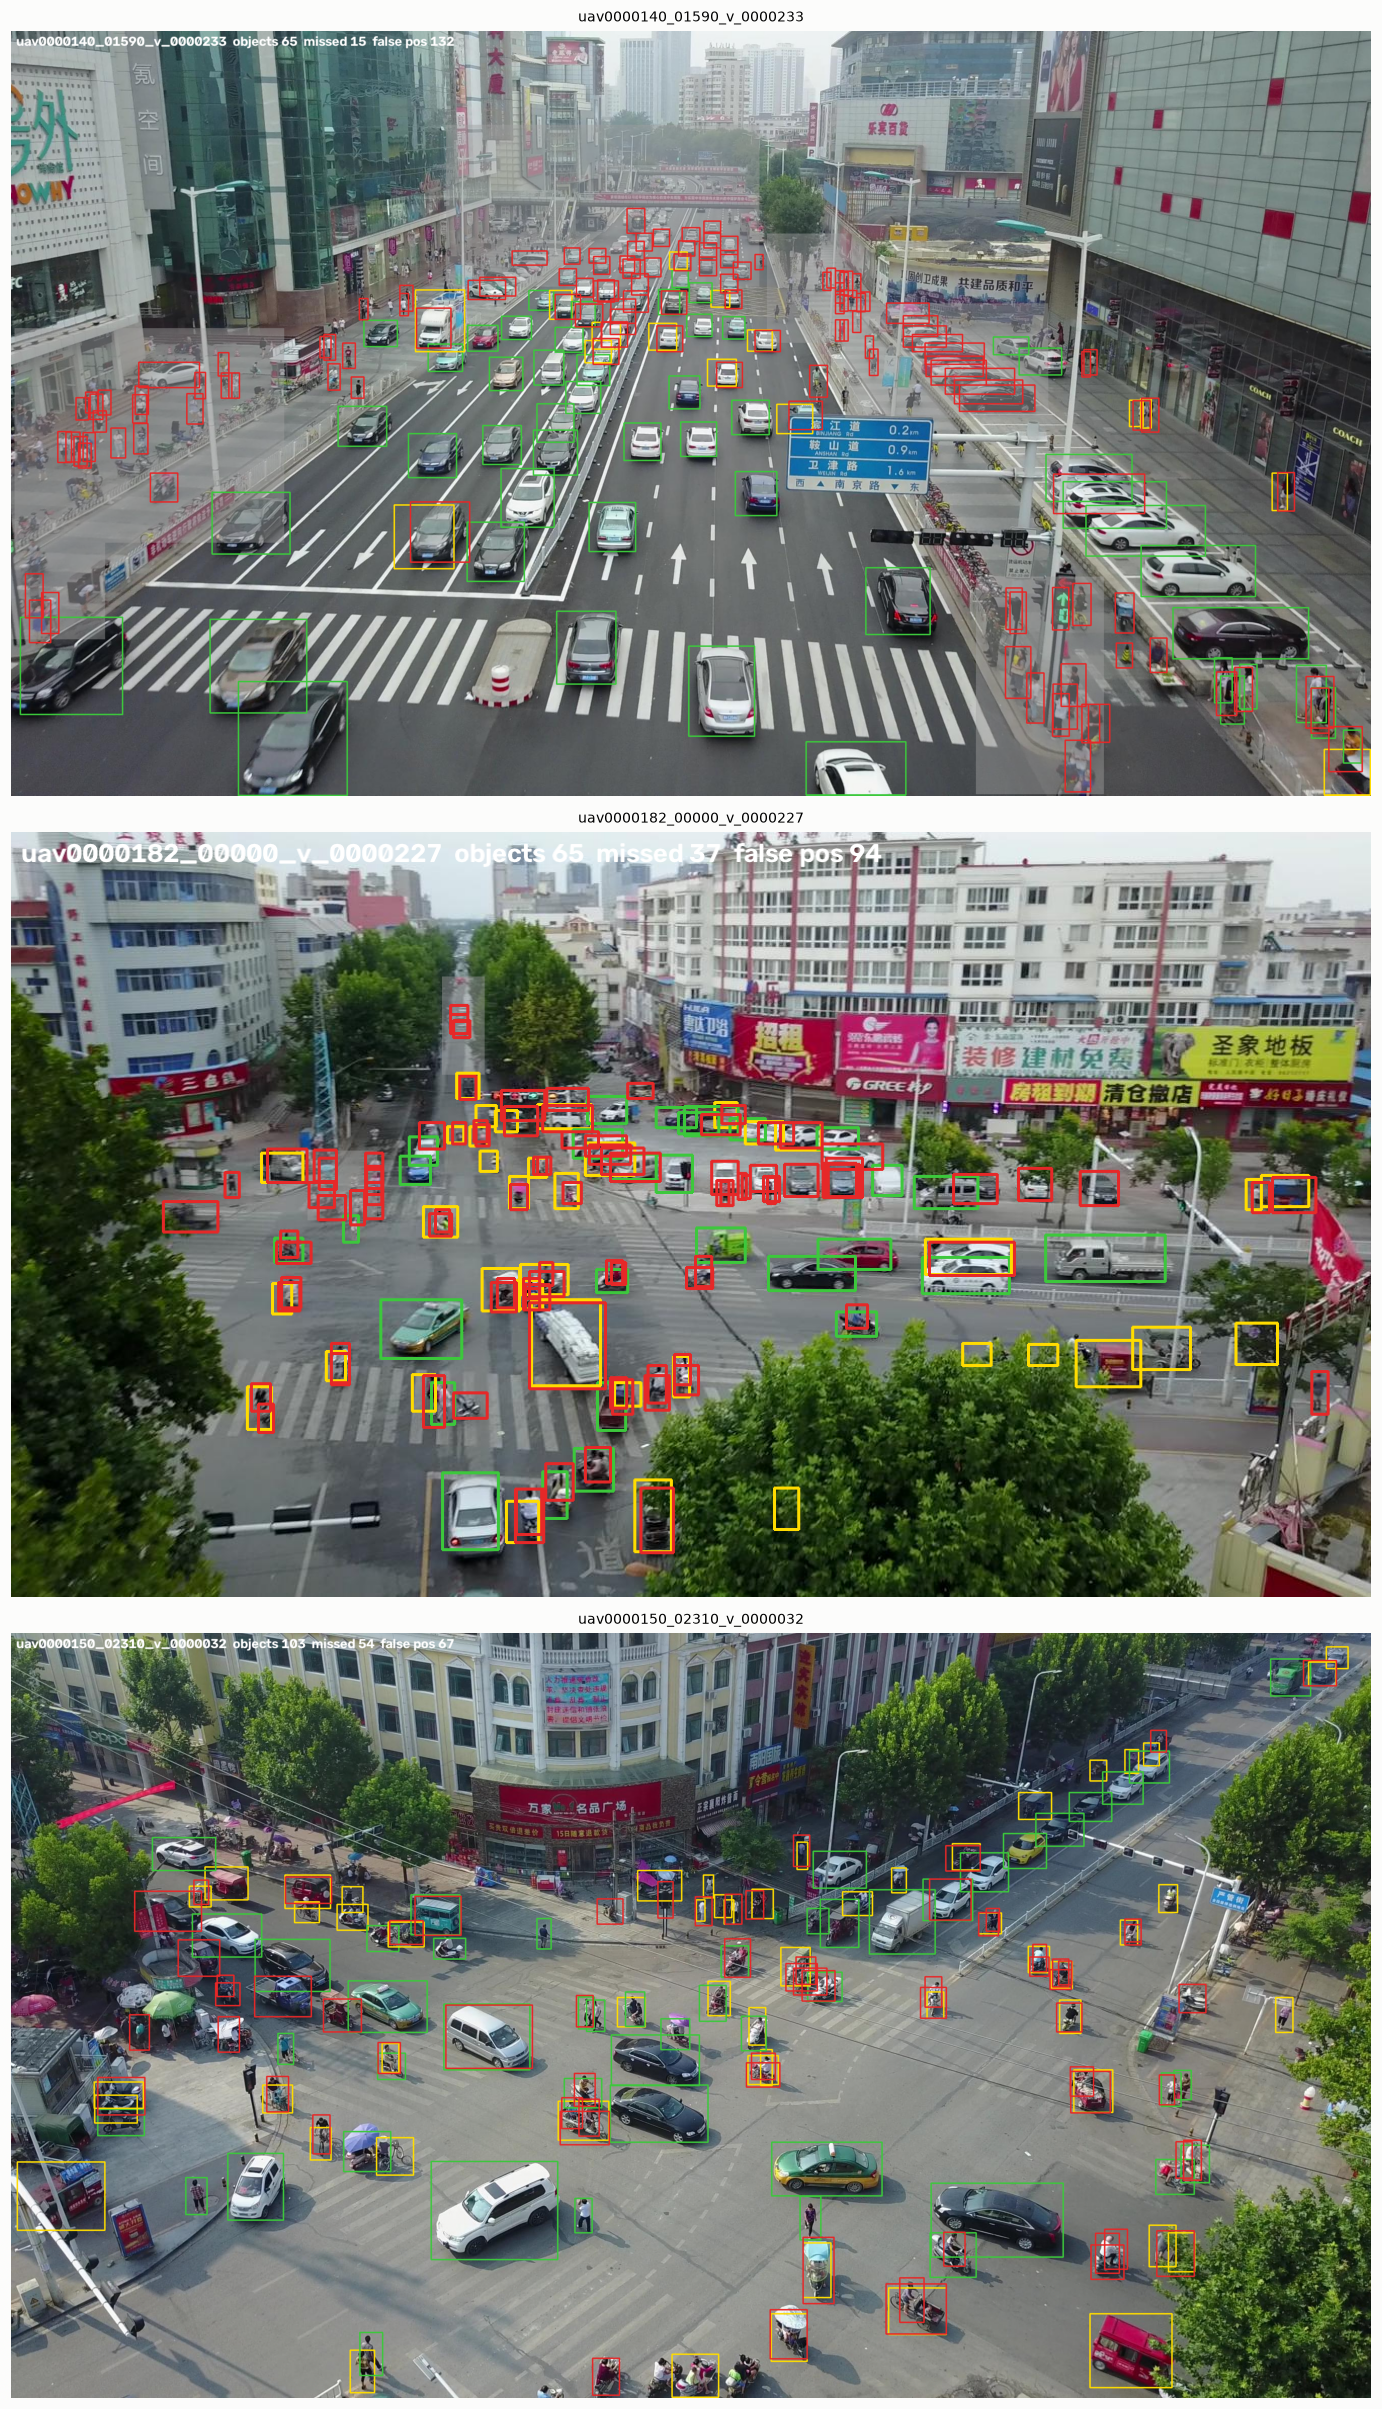

In [7]:
worst = results.worst_frames(tables, pred, n=3)
fig, axes = plt.subplots(3, 1, figsize=(13, 22))
for ax, image_id in zip(axes, worst["image_id"], strict=False):
    ax.imshow(gallery.render(tables, pred, image_id, threshold=0.3)[:, :, ::-1])
    ax.set_title(image_id, fontsize=9)
    ax.axis("off")
fig.tight_layout()

## Conclusions
- More RPN proposals is the only two-stage change that helps (+0.009 mAP); RoI sampling and the GIoU loss are within run-to-run noise (about 0.004) or worse.
- The RPN decides what the detector can find: its top 1000 proposals cover 73% of objects but only 4% of objects under 16 px and 47% of 16-32 px objects, and the final detections stay below that ceiling. Halving the anchor sizes raises AP_small (0.042 to 0.054 in the rerun pair) but the gain in mAP is small.
- The second stage mostly classifies and tightens boxes: false positives at score 0.3 are background (38%), localisation (33%) and class confusion (27%).
- Failure cases: (1) people and parked bicycles on sidewalks without labels, which count as background errors; (2) two-wheelers where motor, bicycle and tricycle and their riders are confused; (3) far, dense regions where small objects are missed.